<a href="https://colab.research.google.com/github/fishpenyet/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PCD - 3rd Assignment**
Name : Naila Syakira
NIM : 25/555286/PA/23270
## Overview
This notebook will implements:
1. Region Growing Segmentation Method (from scratch),
2. Dilation and Erosion morphological operations (from scratch), and
3. Compariso of the segmentation result with or without morphological operations



In [189]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request
import io

In [190]:
from google.colab import files
uploaded = files.upload()
img = Image.open(list(uploaded.keys())[0]).convert("L")
img = np.array(img)

Saving coin.jpeg to coin.jpeg


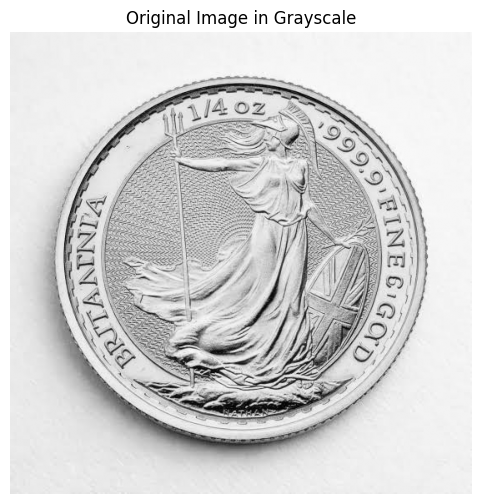

In [191]:
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.title("Original Image in Grayscale")
plt.axis("off")
plt.show()

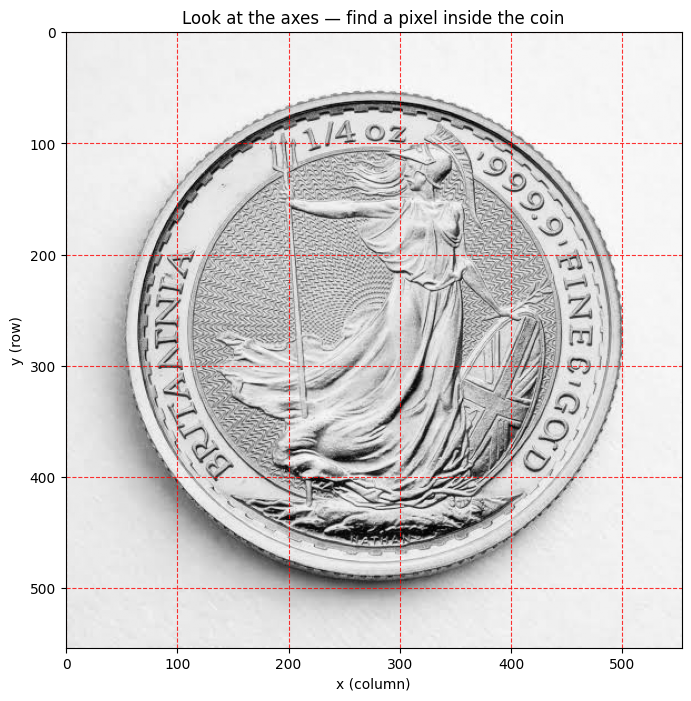

Image size: height=554, width=554

Pixel values at some points inside the coin:
  (221, 221): brightness = 212
  (221, 277): brightness = 127
  (221, 332): brightness = 172
  (277, 221): brightness = 229
  (277, 277): brightness = 193
  (277, 332): brightness = 217
  (332, 221): brightness = 230
  (332, 277): brightness = 196
  (332, 332): brightness = 211


In [192]:
plt.figure(figsize=(8, 8))
plt.imshow(img, cmap="gray")
plt.title("Look at the axes — find a pixel inside the coin")
plt.xlabel("x (column)")
plt.ylabel("y (row)")
plt.grid(color="red", alpha=0.8, linestyle="--")
plt.show()

h, w = img.shape
print(f"Image size: height={h}, width={w}")
print("\nPixel values at some points inside the coin:")
for y_frac in [0.4, 0.5, 0.6]:
    for x_frac in [0.4, 0.5, 0.6]:
        y = int(h * y_frac)
        x = int(w * x_frac)
        print(f"  ({y}, {x}): brightness = {img[y, x]}")

In [193]:
def region_growing(img, seed, threshold):

    h = img.shape[0]
    w = img.shape[1]

    seed_y = seed[0]
    seed_x = seed[1]
    seed_val = int(img[seed_y, seed_x])

    visited = np.zeros((h, w), dtype=bool)
    mask    = np.zeros((h, w), dtype=bool)

    stack = []
    stack.append((seed_y, seed_x))
    visited[seed_y, seed_x] = True
    mask[seed_y, seed_x]    = True

    while len(stack) > 0:
        current = stack.pop()
        y = current[0]
        x = current[1]

        neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        for direction in neighbors:
            dy = direction[0]
            dx = direction[1]
            ny = y + dy
            nx = x + dx

            if ny < 0 or ny >= h or nx < 0 or nx >= w:
                continue
            if visited[ny, nx]:
                continue

            visited[ny, nx] = True
            neighbor_val = int(img[ny, nx])

            if abs(neighbor_val - seed_val) < threshold:
                mask[ny, nx] = True
                stack.append((ny, nx))

    return mask

print("region_growing() defined")

region_growing() defined


Seed value at (332, 332) = 211
Raw mask: 95402 pixels (out of 306916)
Percentage of image: 31.1%


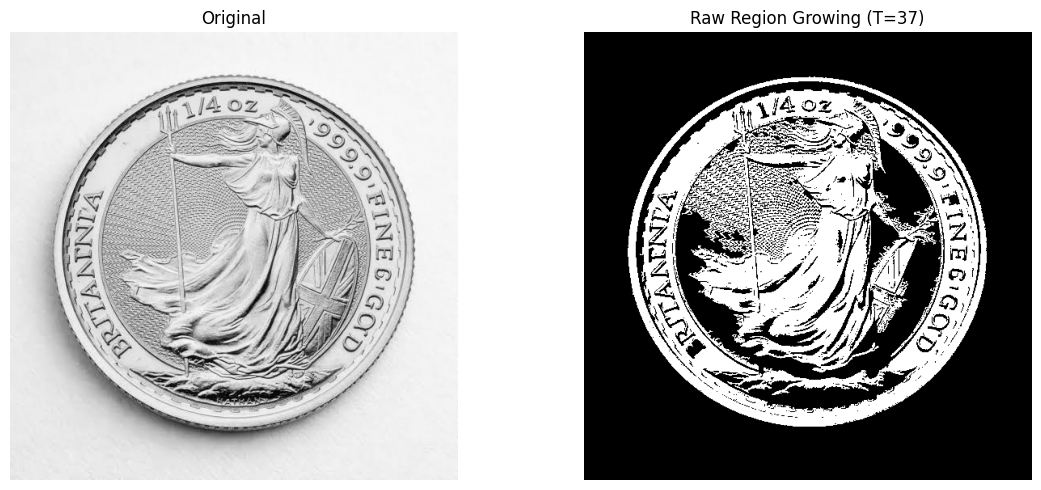

In [194]:
seed_row = 332
seed_col = 332
threshold = 37 # more than this and the background started to be included

print(f"Seed value at ({seed_row}, {seed_col}) = {img[seed_row, seed_col]}")

mask_raw = region_growing(img, (seed_row, seed_col), threshold)
print(f"Raw mask: {mask_raw.sum()} pixels (out of {mask_raw.size})")
print(f"Percentage of image: {100 * mask_raw.sum() / mask_raw.size:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original"); axes[0].axis("off")

axes[1].imshow(mask_raw, cmap="gray")
axes[1].set_title(f"Raw Region Growing (T={threshold})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [195]:
def dilate(binary_img):
    h = binary_img.shape[0]
    w = binary_img.shape[1]
    out = np.zeros((h, w), dtype=np.uint8)

    se = [(-1,-1), (-1,0), (-1,1),
          ( 0,-1), ( 0,0), ( 0,1),
          ( 1,-1), ( 1,0), ( 1,1)]

    for y in range(h):
        for x in range(w):
            for direction in se:
                dy = direction[0]
                dx = direction[1]
                ny = y + dy
                nx = x + dx

                if 0 <= ny < h and 0 <= nx < w:
                    if binary_img[ny, nx] == 1:
                        out[y, x] = 1
                        break
    return out

In [196]:
def erode(binary_img):
    h = binary_img.shape[0]
    w = binary_img.shape[1]
    out = np.zeros((h, w), dtype=np.uint8)

    se = [(-1,-1), (-1,0), (-1,1),
          ( 0,-1), ( 0,0), ( 0,1),
          ( 1,-1), ( 1,0), ( 1,1)]

    for y in range(h):
        for x in range(w):
            if binary_img[y, x] == 0:
                continue

            keep = True
            for direction in se:
                dy = direction[0]
                dx = direction[1]
                ny = y + dy
                nx = x + dx

                if ny < 0 or ny >= h or nx < 0 or nx >= w:
                    keep = False
                    break
                if binary_img[ny, nx] == 0:
                    keep = False
                    break

            if keep:
                out[y, x] = 1
    return out

In [197]:
def closing_large(binary_img, n):
    temp = binary_img.copy()
    for _ in range(n):
        temp = dilate(temp)

    for _ in range(n-1):
        temp = erode(temp)

    return temp

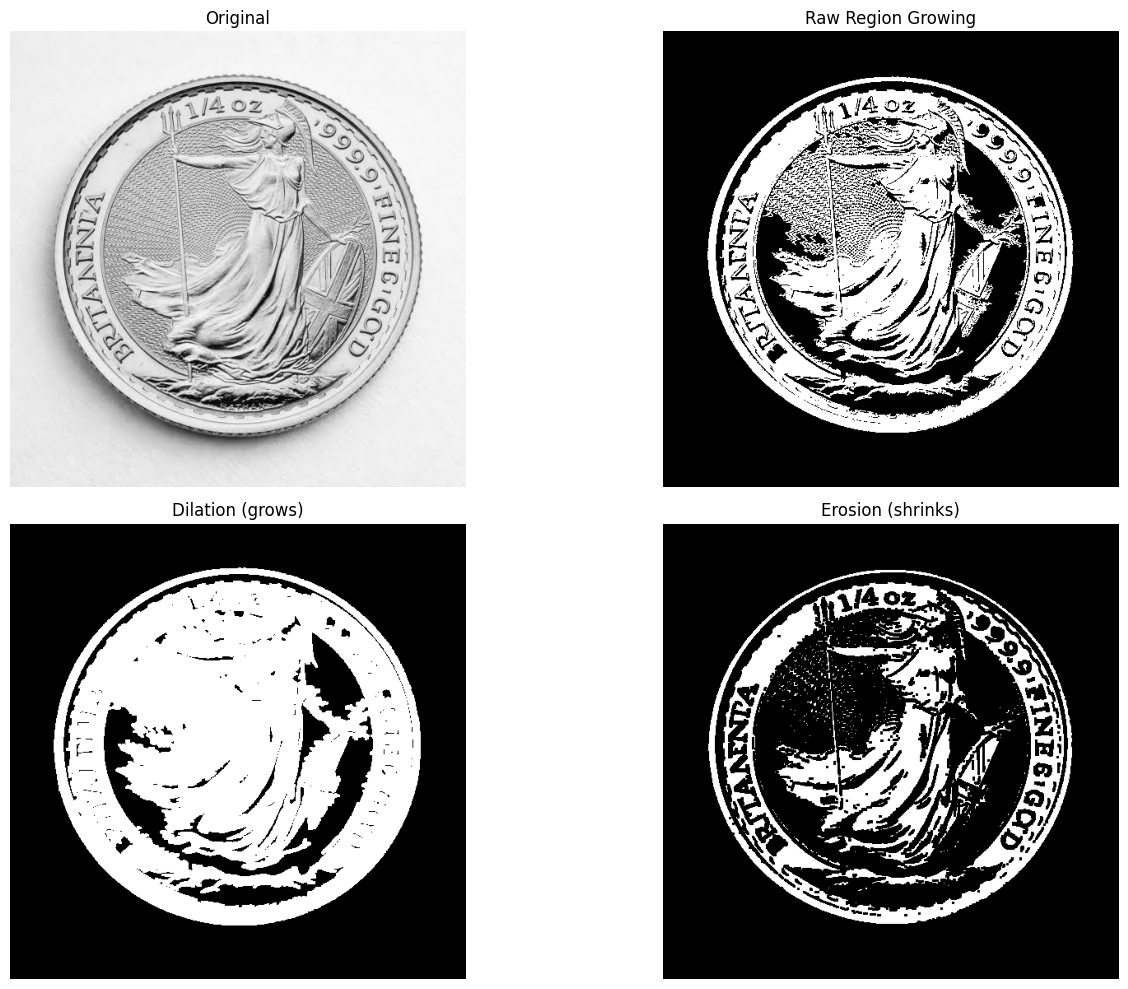

In [200]:
binary_mask = mask_raw.astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0,0].imshow(img, cmap="gray"); axes[0,0].set_title("Original"); axes[0,0].axis("off")
axes[0,1].imshow(binary_mask, cmap="gray"); axes[0,1].set_title("Raw Region Growing"); axes[0,1].axis("off")
axes[1,0].imshow(dilate(binary_mask), cmap="gray"); axes[1,0].set_title("Dilation (grows)"); axes[1,0].axis("off")
axes[1,1].imshow(erode(binary_mask), cmap="gray");  axes[1,1].set_title("Erosion (shrinks)"); axes[1,1].axis("off")

plt.tight_layout()
plt.show()


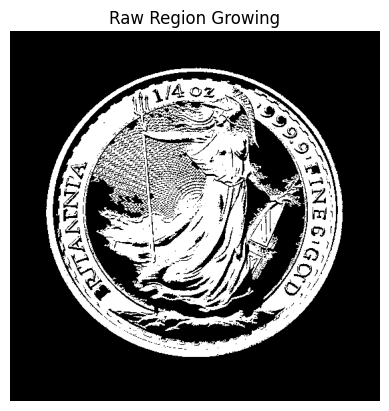

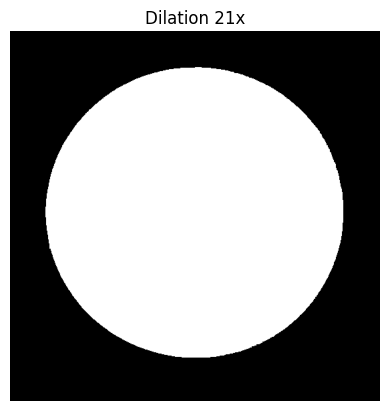

In [199]:
heavy_dilated = closing_large(binary_mask, 21)

plt.imshow(binary_mask, cmap="gray")
plt.title("Raw Region Growing")
plt.axis("off")
plt.show()

plt.imshow(heavy_dilated, cmap="gray")
plt.title("Dilation 21x")
plt.axis("off")
plt.show()